## Simple MultiAI Agent Architecture

In [4]:
from dotenv import load_dotenv
import os

from langchain.chat_models import init_chat_model
from langchain_core.messages import SystemMessage
from langchain_core.tools import tool
from langchain_community.tools.tavily_search import TavilySearchResults

from langgraph.graph import StateGraph, END, MessagesState
from langgraph.prebuilt import ToolNode

In [5]:
load_dotenv()

if not os.getenv("GROQ_API_KEY"):
    raise ValueError("GROQ_API_KEY is missing")

llm = init_chat_model("groq:openai/gpt-oss-20b")

In [6]:
@tool
def search_web(query: str) -> str:
    """Search the web for information."""
    search = TavilySearchResults(max_results=3)
    return str(search.invoke(query))

In [7]:
def researcher_agent(state: MessagesState):
    system_msg = SystemMessage(
        content=(
            "You are a research assistant. "
            "Research the user's topic using web search. "
            "After reviewing the search results, provide "
            "your research findings."
        )
    )

    researcher_llm = llm.bind_tools([search_web])

    response = researcher_llm.invoke(
        [system_msg] + state["messages"]
    )

    return {"messages": [response]}

In [8]:
def writer_agent(state: MessagesState):
    system_msg = SystemMessage(
        content=(
            "You are a technical writer. "
            "Use the research findings in the conversation "
            "to create a clear, concise, structured summary."
        )
    )

    response = llm.invoke(
        [system_msg] + state["messages"]
    )

    return {"messages": [response]}


In [11]:
def route_after_research(state: MessagesState):
    last_message = state["messages"][-1]

    if getattr(last_message, "tool_calls", []):
        return "needs_search"

    return "research_complete"

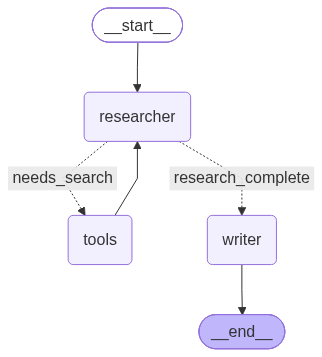

In [14]:
workflow = StateGraph(MessagesState)

workflow.add_node("researcher", researcher_agent)
workflow.add_node("tools", ToolNode([search_web]))
workflow.add_node("writer", writer_agent)

workflow.set_entry_point("researcher")

workflow.add_conditional_edges(
    "researcher",
    route_after_research,
    {
        "needs_search": "tools", # The left side is the routing function's return value. The right side is the graph node name.
        "research_complete": "writer"
    }
)

# After executing the search, let the researcher
# inspect the tool result and decide what to do next.
workflow.add_edge("tools", "researcher")

workflow.add_edge("writer", END)

final_workflow = workflow.compile()

final_workflow

In [15]:
response = final_workflow.invoke({
    "messages": [
        {
            "role": "user",
            "content": (
                "Research business use cases of Agentic AI"
            )
        }
    ]
})

response

{'messages': [HumanMessage(content='Research business use cases of Agentic AI', additional_kwargs={}, response_metadata={}, id='15a1ea3a-e892-4652-8924-b9e30318bce3'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user wants research business use cases of Agentic AI. We need to search web. Use search_web function. We\'ll search for "business use cases of agentic AI".', 'tool_calls': [{'id': 'fc_7aa3cc51-dc6d-4432-b197-0fa72cf7cfaa', 'function': {'arguments': '{"query":"business use cases of agentic AI"}', 'name': 'search_web'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 65, 'prompt_tokens': 155, 'total_tokens': 220, 'completion_time': 0.071739663, 'completion_tokens_details': {'reasoning_tokens': 36}, 'prompt_time': 0.008776023, 'prompt_tokens_details': None, 'queue_time': 0.337456522, 'total_time': 0.080515686}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_a4315eb300', 'service_tier': 'on_demand', 'finish_reas

In [16]:
print(response["messages"][-1].content)

**Agentic AI in Business – Structured Summary of Key Use Cases**

| **Business Function** | **Typical Agentic AI Use‑Case** | **Core Capabilities** | **Typical Business Value** |
|------------------------|--------------------------------|-----------------------|---------------------------|
| **Customer Support** | 24/7 “smart” ticketing agent | • Reads ticket history & CRM data<br>• Generates responses, auto‑creates tickets, escalates when needed | • 30–50 % faster average handle time<br>• ↑ first‑contact resolution (FCR) & CSAT |
| **E‑commerce & Retail** | Personal shopping assistant | • Tracks browsing, purchase history, inventory & pricing<br>• Curates product bundles & updates cart | • 10–15 % lift in conversion rate<br>• ↑ average order value (AOV) |
| **Human Resources (Recruiting/Onboarding)** | End‑to‑end hiring agent | • Screens CVs, schedules interviews, sends welcome packets, tracks milestones | • 30–40 % faster time‑to‑hire<br>• Consistent compliance |
| **Finance & Procur